# Grenzflächen und dünne Schichten

Dieses Notebook behandelt `pyoptics.interfaces` (Fresnel-Koeffizienten einer
einzelnen Grenzfläche) und `pyoptics.thin_films` (Transfermatrix-Rechnung für
Schichtstapel). Themen: Brewster-Winkel, Totalreflexion mit evaneszenter
Welle, Metallreflexion, Seifenhautfarben, Antireflexschicht, Bragg-Spiegel,
dicke (inkohärente) Platten und dünne Metallfilme.

**Konvention:** $\exp(i(\mathbf{k}\cdot\mathbf{r} - \omega t))$, absorbierende
Medien haben $\tilde n = n + i\kappa$ mit $\kappa > 0$. Der gebrochene Winkel wird
so gewählt, dass die transmittierte Welle von der Grenzfläche weg abklingt.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

from pyoptics import interfaces as itf
from pyoptics import thin_films as tf

plt.rcParams.update({"figure.dpi": 100, "image.origin": "lower", "font.size": 11})
deg = np.pi/180

## 1. Fresnel-Koeffizienten: Luft → Glas

Für s-Polarisation (E senkrecht zur Einfallsebene) und p-Polarisation
(E in der Einfallsebene) gelten verschiedene Fresnel-Formeln. Beim
**Brewster-Winkel** $\theta_B = \arctan(n_2/n_1)$ verschwindet $r_p$: Reflektierter
und gebrochener Strahl stehen senkrecht aufeinander, und die Dipole im Glas
strahlen nicht in Richtung des reflektierten Strahls. Deshalb ist Licht, das
unter $\theta_B$ reflektiert wird, rein s-polarisiert.

Die Energieerhaltung $R + T = 1$ gilt mit $T = \frac{\mathrm{Re}(n_2\cos\theta_2)}{\mathrm{Re}(n_1\cos\theta_1)}|t|^2$,
nicht mit $|t|^2$ allein.

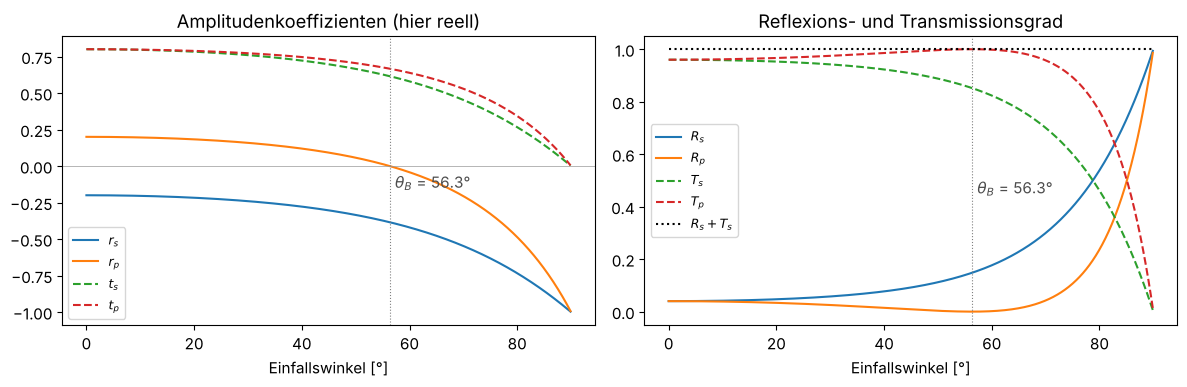

In [2]:
n1, n2 = 1.0, 1.5
theta = np.linspace(0, 89.9, 900)*deg
theta_B = itf.brewster_angle(n1, n2)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(theta/deg, itf.r_s(theta, n1, n2).real, label="$r_s$")
axes[0].plot(theta/deg, itf.r_p(theta, n1, n2).real, label="$r_p$")
axes[0].plot(theta/deg, itf.t_s(theta, n1, n2).real, "--", label="$t_s$")
axes[0].plot(theta/deg, itf.t_p(theta, n1, n2).real, "--", label="$t_p$")
axes[0].axhline(0, color="0.6", lw=0.5)
axes[0].set_title("Amplitudenkoeffizienten (hier reell)")
axes[1].plot(theta/deg, itf.R_s(theta, n1, n2), label="$R_s$")
axes[1].plot(theta/deg, itf.R_p(theta, n1, n2), label="$R_p$")
axes[1].plot(theta/deg, itf.T_s(theta, n1, n2), "--", label="$T_s$")
axes[1].plot(theta/deg, itf.T_p(theta, n1, n2), "--", label="$T_p$")
axes[1].plot(theta/deg, itf.R_s(theta, n1, n2) + itf.T_s(theta, n1, n2), "k:", label="$R_s + T_s$")
axes[1].set_title("Reflexions- und Transmissionsgrad")
for ax in axes:
    ax.axvline(theta_B/deg, color="0.5", lw=0.8, ls=":")
    ax.text(theta_B/deg + 1, -0.15 if ax is axes[0] else 0.45, f"$\\theta_B$ = {theta_B/deg:.1f}°", color="0.3")
    ax.set_xlabel("Einfallswinkel [°]"); ax.legend(fontsize=9)
fig.tight_layout()

## 2. Glas → Luft: Totalreflexion und evaneszente Welle

Oberhalb des **Grenzwinkels** $\theta_c = \arcsin(n_2/n_1)$ wird alles reflektiert,
$|r_s| = |r_p| = 1$. Die Reflexionskoeffizienten sind dann komplex: s- und
p-Anteil erhalten **verschiedene Phasensprünge**. Aus linear polarisiertem
Licht wird so elliptisch polarisiertes (Fresnel-Rhombus, siehe Notebook 04).

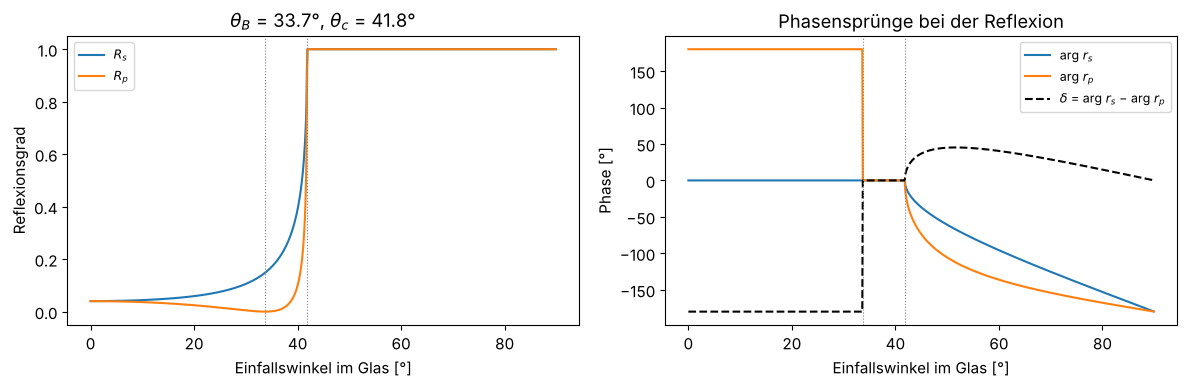

In [3]:
n1, n2 = 1.5, 1.0
theta_c = np.real(itf.critical_angle(n1, n2))
theta_B = itf.brewster_angle(n1, n2)
rs, rp = itf.r_s(theta, n1, n2), itf.r_p(theta, n1, n2)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(theta/deg, np.abs(rs)**2, label="$R_s$")
axes[0].plot(theta/deg, np.abs(rp)**2, label="$R_p$")
axes[0].set_ylabel("Reflexionsgrad")
axes[1].plot(theta/deg, np.angle(rs)/deg, label="arg $r_s$")
axes[1].plot(theta/deg, np.angle(rp)/deg, label="arg $r_p$")
axes[1].plot(theta/deg, (np.angle(rs) - np.angle(rp))/deg, "k--", label="$\\delta$ = arg $r_s$ − arg $r_p$")
axes[1].set_ylabel("Phase [°]")
for ax in axes:
    ax.axvline(theta_c/deg, color="0.5", lw=0.8, ls=":")
    ax.axvline(theta_B/deg, color="0.5", lw=0.8, ls=":")
    ax.set_xlabel("Einfallswinkel im Glas [°]"); ax.legend(fontsize=9)
axes[0].set_title(f"$\\theta_B$ = {theta_B/deg:.1f}°, $\\theta_c$ = {theta_c/deg:.1f}°")
axes[1].set_title("Phasensprünge bei der Reflexion")
fig.tight_layout()

Wie sieht das Feld an der Grenzfläche aus? Für s-Polarisation ist $E_y$ im Glas
($z<0$) die Summe aus einfallender und reflektierter Welle, in der Luft ($z>0$)
die transmittierte Welle

$$E_y = t_s\, e^{i(k_x x + k_{z,2} z)}, \qquad k_{z,2} = n_2 k_0 \cos\theta_2 .$$

Unter Totalreflexion ist $\cos\theta_2$ (aus `refracted_angle()`) rein imaginär
mit positivem Imaginärteil: Die Welle läuft entlang der Grenzfläche und klingt
in $z$ exponentiell ab, mit der Eindringtiefe
$d = 1/\mathrm{Im}\,k_{z,2} = \lambda/(2\pi\sqrt{n_1^2\sin^2\theta - n_2^2})$.
Gezeigt ist eine Momentaufnahme $\mathrm{Re}\,E_y$.

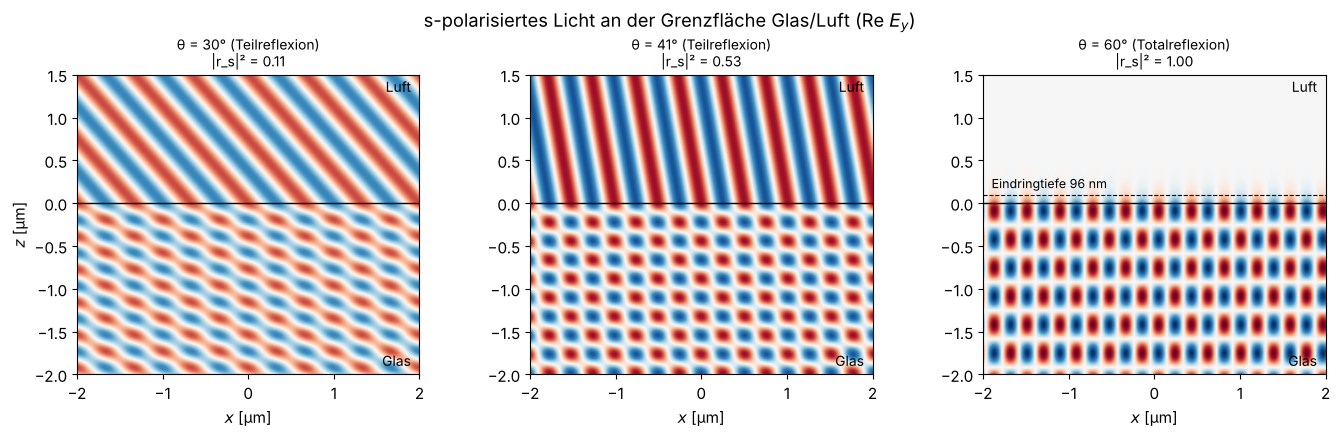

In [4]:
wl = 0.5
k0 = 2*np.pi/wl
xg = np.linspace(-2, 2, 400)
zg = np.linspace(-2, 1.5, 350)
Xg, Zg = np.meshgrid(xg, zg)

fig, axes = plt.subplots(1, 3, figsize=(14, 4.2))
for ax, th_deg in zip(axes, (30, 41, 60)):
    th = th_deg*deg
    th2 = itf.refracted_angle(th, n1, n2)
    kx = n1*k0*np.sin(th)
    kz1 = n1*k0*np.cos(th)
    kz2 = n2*k0*np.cos(th2)
    r, t = itf.r_s(th, n1, n2), itf.t_s(th, n1, n2)
    E = np.where(Zg < 0,
                 np.exp(1j*(kx*Xg + kz1*Zg)) + r*np.exp(1j*(kx*Xg - kz1*Zg)),
                 t*np.exp(1j*(kx*Xg + kz2*Zg)))
    ax.imshow(np.real(E), extent=(xg[0], xg[-1], zg[0], zg[-1]), cmap="RdBu_r", vmin=-2, vmax=2)
    ax.axhline(0, color="k", lw=1)
    label = "Totalreflexion" if th > theta_c else "Teilreflexion"
    ax.set_title(f"θ = {th_deg}° ({label})\n|r_s|² = {abs(r)**2:.2f}", fontsize=10)
    ax.set_xlabel("$x$ [µm]")
    if th > theta_c:
        d = 1/np.imag(kz2)
        ax.axhline(d, color="k", ls="--", lw=0.8)
        ax.text(-1.9, d + 0.08, f"Eindringtiefe {1000*d:.0f} nm", fontsize=9)
    ax.text(1.9, -1.9, "Glas", ha="right", fontsize=10); ax.text(1.9, 1.3, "Luft", ha="right", fontsize=10)
axes[0].set_ylabel("$z$ [µm]")
fig.suptitle("s-polarisiertes Licht an der Grenzfläche Glas/Luft (Re $E_y$)")
fig.tight_layout()

## 3. Reflexion an Metallen

Metalle haben einen großen Imaginärteil des Brechungsindex. $R_p$ hat dann
keine echte Nullstelle mehr, sondern ein Minimum beim *Hauptwinkel*
(Pseudo-Brewster-Winkel). Ellipsometrie nutzt die Phasendifferenz
$\delta = \arg r_s - \arg r_p$, um $n$ und $\kappa$ zu bestimmen: Sie fällt von
$180°$ (senkrechter Einfall, wo in der Hecht-Konvention $r_p = -r_s$ gilt) auf $0°$
(streifender Einfall) und ist beim Hauptwinkel (Punkte) genau $90°$. Beim Glas
springt sie dagegen am Brewster-Winkel von $180°$ auf $0°$.

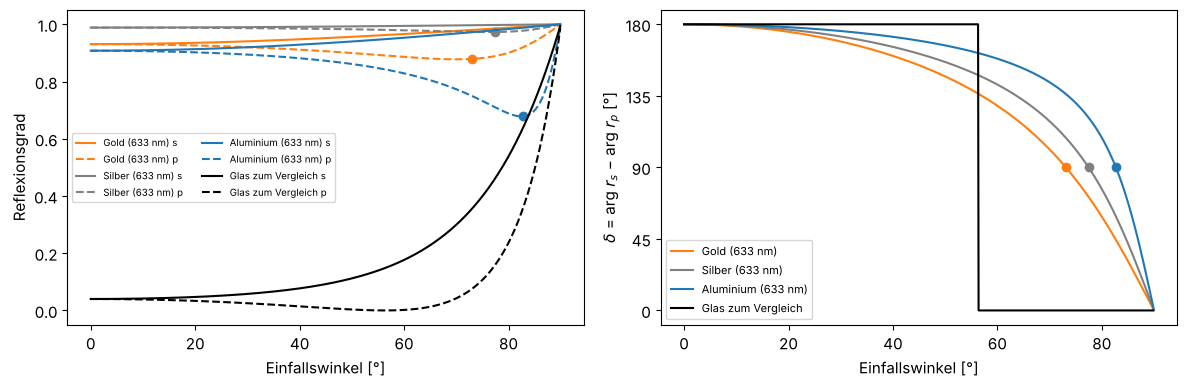

In [5]:
metals = {"Gold (633 nm)": 0.18 + 3.0j, "Silber (633 nm)": 0.056 + 4.28j, "Aluminium (633 nm)": 1.45 + 7.54j,
          "Glas zum Vergleich": 1.5 + 0j}
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for (name, nm), c in zip(metals.items(), ("C1", "0.5", "C0", "k")):
    axes[0].plot(theta/deg, itf.R_s(theta, 1.0, nm), color=c, ls="-", label=name + " s")
    axes[0].plot(theta/deg, itf.R_p(theta, 1.0, nm), color=c, ls="--", label=name + " p")
    delta = np.mod((np.angle(itf.r_s(theta, 1.0, nm)) - np.angle(itf.r_p(theta, 1.0, nm)))/deg + 1e-9, 360)
    axes[1].plot(theta/deg, delta, color=c, label=name)
    if nm.imag > 0:
        i90 = np.argmin(np.abs(delta - 90))
        axes[1].plot(theta[i90]/deg, 90, "o", color=c)
        axes[0].plot(theta[i90]/deg, itf.R_p(theta[i90], 1.0, nm), "o", color=c)
axes[0].set_ylabel("Reflexionsgrad"); axes[0].legend(fontsize=7, ncol=2)
axes[1].set_ylabel("$\\delta$ = arg $r_s$ − arg $r_p$ [°]"); axes[1].legend(fontsize=8)
axes[1].set_yticks([0, 45, 90, 135, 180])
for ax in axes:
    ax.set_xlabel("Einfallswinkel [°]")
fig.tight_layout()

## 4. Dünne Schichten: die Transfermatrix

`thin_films.r_t_coeffs()` berechnet die Amplitudenkoeffizienten eines
Schichtstapels (Zangwill/McLeod), `R_T_A_coeffs()` die Intensitäten und die
Absorption $A = 1 - R - T$. Zur Kontrolle: Eine Schicht der Dicke null muss die
nackte Grenzfläche ergeben.

Hinweis: `thin_films` bezieht $r$ und $t$ auf die **tangentialen** Feldkomponenten.
Für p-Polarisation unterscheidet sich das Vorzeichen von $r_p$ deshalb von der
Hecht-Konvention in `interfaces`, die Intensitäten sind gleich.

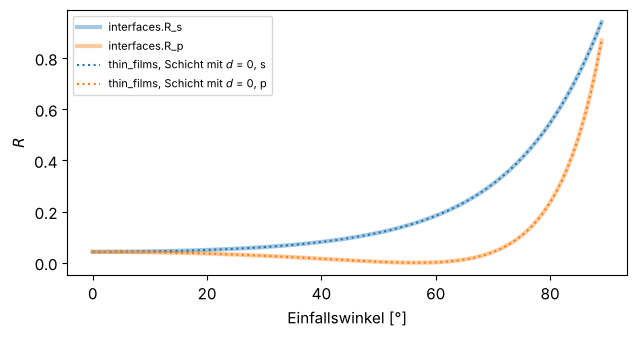

In [6]:
def stack_RTA(theta, wl, n, k, t, n_emb=1.0, n_sub=1.52, k_sub=0.0, pol="s", **kw):
    return tf.R_T_A_coeffs(theta, n, k, t, n_emb, 0.0, n_sub, k_sub, pol, wl, **kw)

th = np.linspace(0, 89, 90)*deg
R_stack = {pol: [stack_RTA(a, 0.55, [1.38], [0.0], [0.0], pol=pol)[0] for a in th] for pol in "sp"}
fig, ax = plt.subplots(figsize=(6.5, 3.5))
ax.plot(th/deg, itf.R_s(th, 1.0, 1.52), "C0", lw=3, alpha=0.4, label="interfaces.R_s")
ax.plot(th/deg, itf.R_p(th, 1.0, 1.52), "C1", lw=3, alpha=0.4, label="interfaces.R_p")
ax.plot(th/deg, R_stack["s"], "C0:", label="thin_films, Schicht mit $d$ = 0, s")
ax.plot(th/deg, R_stack["p"], "C1:", label="thin_films, Schicht mit $d$ = 0, p")
ax.set_xlabel("Einfallswinkel [°]"); ax.set_ylabel("$R$"); ax.legend(fontsize=8)
fig.tight_layout()

### 4.1 Farben einer Seifenhaut

Eine Wasserschicht ($n = 1.33$) in Luft reflektiert je nach Dicke andere
Wellenlängen bevorzugt. Wir berechnen $R(\lambda)$ für senkrechten Einfall und
rechnen das Spektrum mit den CIE-1931-Normspektralwertfunktionen (analytische
Näherung nach Wyman, Sloan und Shirley) in sRGB-Farben um. Beleuchtung:
energiegleiches Weiß; die Helligkeit ist zur besseren Sichtbarkeit verstärkt.

Ganz dünne Filme erscheinen **schwarz**: Die Reflexion an der Vorderseite
(dünn → dicht) hat gegenüber der an der Rückseite einen Phasensprung von $\pi$,
bei $d \to 0$ löschen sich beide Anteile aus. Mit zunehmender Dicke folgen
Weiß, Gelb, Purpur, Blau, ... (Newtonsche Farbfolge), bis die Farben bei
einigen µm verblassen, weil sich die Interferenzmaxima vieler Ordnungen
im sichtbaren Spektrum überlagern.

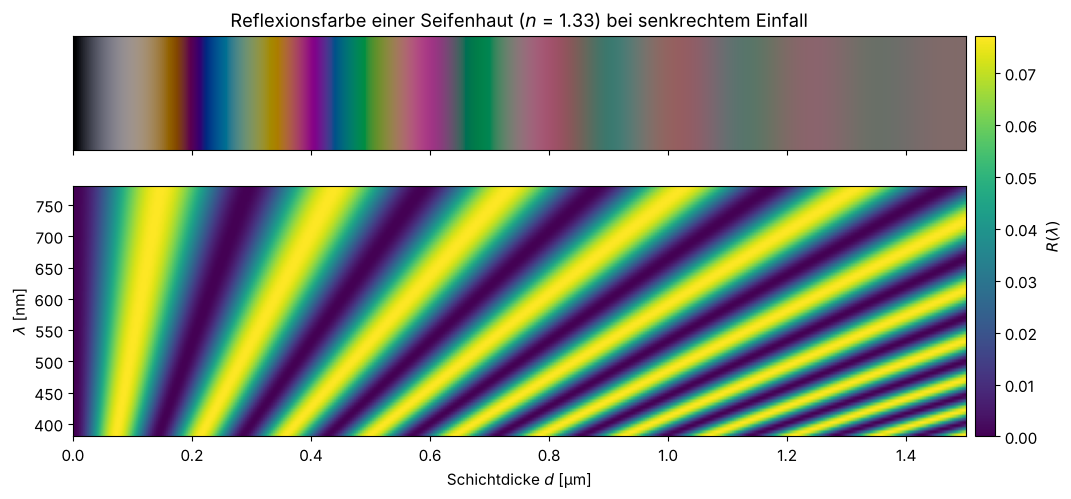

In [7]:
def _g(lam, mu, s1, s2):
    s = np.where(lam < mu, s1, s2)
    return np.exp(-0.5*(lam - mu)**2/s**2)

def cie_xyz(lam_nm):
    xb = 1.056*_g(lam_nm, 599.8, 37.9, 31.0) + 0.362*_g(lam_nm, 442.0, 16.0, 26.7) - 0.065*_g(lam_nm, 501.1, 20.4, 26.2)
    yb = 0.821*_g(lam_nm, 568.8, 46.9, 40.5) + 0.286*_g(lam_nm, 530.9, 16.3, 31.1)
    zb = 1.217*_g(lam_nm, 437.0, 11.8, 36.0) + 0.681*_g(lam_nm, 459.0, 26.0, 13.8)
    return np.array([xb, yb, zb])

M_XYZ_to_sRGB = np.array([[3.2406, -1.5372, -0.4986], [-0.9689, 1.8758, 0.0415], [0.0557, -0.2040, 1.0570]])

def spectrum_to_rgb(lam_nm, S, gain=1.0):
    cmf = cie_xyz(lam_nm)
    XYZ = cmf @ S/np.sum(cmf[1])     # S = 1 überall -> Y = 1 (weiß)
    rgb = np.clip(gain*(M_XYZ_to_sRGB @ XYZ), 0, 1)
    return np.where(rgb <= 0.0031308, 12.92*rgb, 1.055*rgb**(1/2.4) - 0.055)  # sRGB-Gamma

lam = np.linspace(380, 780, 81)
d_vals = np.linspace(0, 1.5, 451)  # Dicke in µm
R_map = np.array([[stack_RTA(0.0, l/1000, [1.33], [0.0], [d], n_sub=1.0)[0] for l in lam] for d in d_vals])
colors = np.array([spectrum_to_rgb(lam, R, gain=4.0) for R in R_map])

fig, axes = plt.subplots(2, 1, figsize=(12, 5.2), gridspec_kw={"height_ratios": [1, 2.2]}, sharex=True)
axes[0].imshow(colors[np.newaxis, :, :], extent=(d_vals[0], d_vals[-1], 0, 1), aspect="auto")
axes[0].set_yticks([]); axes[0].set_title("Reflexionsfarbe einer Seifenhaut ($n$ = 1.33) bei senkrechtem Einfall")
im = axes[1].imshow(R_map.T, extent=(d_vals[0], d_vals[-1], lam[0], lam[-1]), aspect="auto", cmap="viridis")
axes[1].set_xlabel("Schichtdicke $d$ [µm]"); axes[1].set_ylabel("$\\lambda$ [nm]")
fig.colorbar(im, ax=axes, label="$R(\\lambda)$", fraction=0.03, pad=0.01)

### 4.2 Antireflexschicht

Eine Schicht der optischen Dicke $\lambda_0/4$ lässt die Reflexe an Vorder- und
Rückseite mit $\pi$ Phasenunterschied interferieren. Sie löschen sich ganz aus,
wenn beide gleich stark sind, also für $n_\text{Schicht} = \sqrt{n_\text{Glas}}$.
Das reale MgF$_2$ ($n = 1.38$) kommt dem nahe genug, um die Reflexion von 4.3 %
auf etwa 1.3 % zu senken.

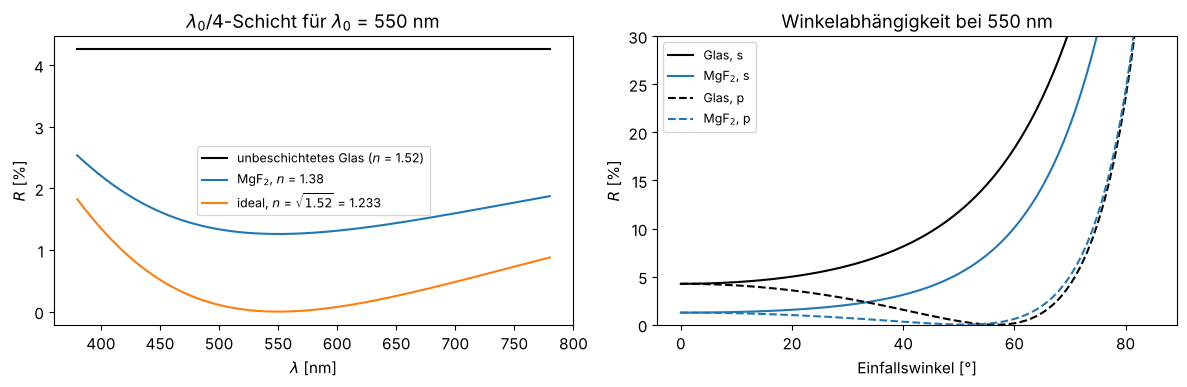

In [8]:
lam = np.linspace(0.38, 0.78, 300)
lam0 = 0.55
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
R_bare = [stack_RTA(0.0, l, [1.0], [0.0], [0.0])[0] for l in lam]
axes[0].plot(lam*1000, np.array(R_bare)*100, "k", label="unbeschichtetes Glas ($n$ = 1.52)")
for n_c, lab in ((1.38, "MgF$_2$, $n$ = 1.38"), (np.sqrt(1.52), f"ideal, $n$ = $\\sqrt{{1.52}}$ = {np.sqrt(1.52):.3f}")):
    R = [stack_RTA(0.0, l, [n_c], [0.0], [lam0/(4*n_c)])[0] for l in lam]
    axes[0].plot(lam*1000, np.array(R)*100, label=lab)
axes[0].set_xlabel("$\\lambda$ [nm]"); axes[0].set_ylabel("$R$ [%]"); axes[0].legend(fontsize=9)
axes[0].set_title(f"$\\lambda_0/4$-Schicht für $\\lambda_0$ = {lam0*1000:.0f} nm")

th = np.linspace(0, 85, 86)*deg
for pol, ls in (("s", "-"), ("p", "--")):
    axes[1].plot(th/deg, [100*stack_RTA(a, lam0, [1.0], [0.0], [0.0], pol=pol)[0] for a in th], "k" + ls, label=f"Glas, {pol}")
    axes[1].plot(th/deg, [100*stack_RTA(a, lam0, [1.38], [0.0], [lam0/(4*1.38)], pol=pol)[0] for a in th], "C0" + ls, label=f"MgF$_2$, {pol}")
axes[1].set_ylim(0, 30); axes[1].set_xlabel("Einfallswinkel [°]"); axes[1].set_ylabel("$R$ [%]")
axes[1].legend(fontsize=9); axes[1].set_title(f"Winkelabhängigkeit bei {lam0*1000:.0f} nm")
fig.tight_layout()

### 4.3 Bragg-Spiegel

Abwechselnde $\lambda_0/4$-Schichten aus hoch- und niedrigbrechendem Material
(TiO$_2$/SiO$_2$) reflektieren in einem **Stoppband** um $\lambda_0$ beinahe
vollständig. Die Reflexion wächst mit der Zahl der Paare, die Breite des
Stoppbands hängt nur vom Indexkontrast ab. In der Frequenz ist es symmetrisch
um $\omega_0$ mit der relativen Breite

$$\frac{\Delta\omega}{\omega_0} = \frac{4}{\pi}\arcsin\frac{n_H - n_L}{n_H + n_L},$$

in der Wellenlänge liegt es deshalb asymmetrisch, mit Rändern bei
$\lambda_0/(1 \pm \Delta\omega/2\omega_0)$.

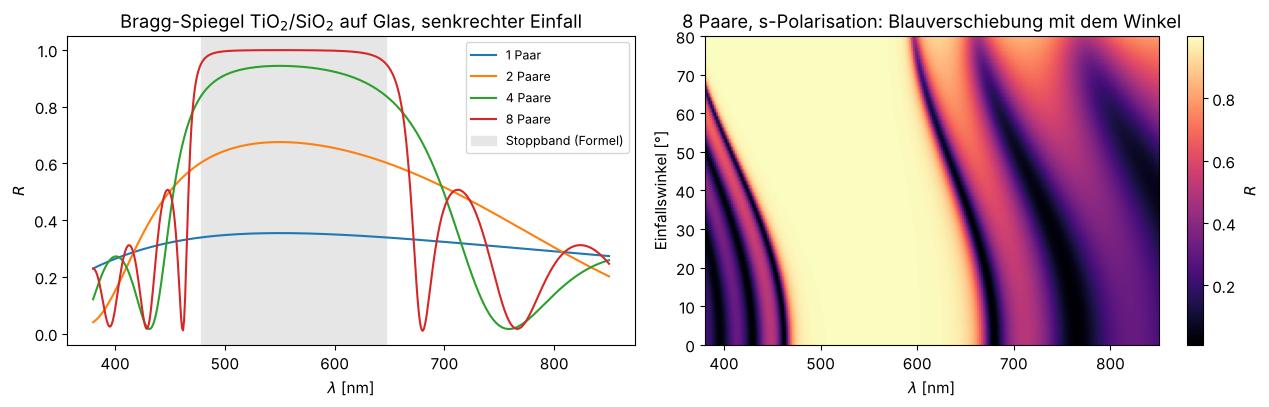

In [9]:
nH, nL = 2.35, 1.46
lam0 = 0.55
def bragg(N_pairs):
    n = [nH, nL]*N_pairs
    t = [lam0/(4*nH), lam0/(4*nL)]*N_pairs
    return n, [0.0]*len(n), t

lam = np.linspace(0.38, 0.85, 500)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
for N_pairs in (1, 2, 4, 8):
    n, k, t = bragg(N_pairs)
    axes[0].plot(lam*1000, [stack_RTA(0.0, l, n, k, t)[0] for l in lam], label=f"{N_pairs} Paar" + ("e" if N_pairs > 1 else ""))
dw = 4/np.pi*np.arcsin((nH - nL)/(nH + nL))
axes[0].axvspan(lam0/(1 + dw/2)*1000, lam0/(1 - dw/2)*1000, color="0.9", zorder=-1, label="Stoppband (Formel)")
axes[0].set_xlabel("$\\lambda$ [nm]"); axes[0].set_ylabel("$R$"); axes[0].legend(fontsize=9)
axes[0].set_title("Bragg-Spiegel TiO$_2$/SiO$_2$ auf Glas, senkrechter Einfall")

n, k, t = bragg(8)
th = np.linspace(0, 80, 81)*deg
lam_map = np.linspace(0.38, 0.85, 240)
R_s = np.array([[stack_RTA(a, l, n, k, t, pol="s")[0] for l in lam_map] for a in th])
im = axes[1].imshow(R_s, extent=(lam_map[0]*1000, lam_map[-1]*1000, 0, 80), aspect="auto", cmap="magma")
axes[1].set_xlabel("$\\lambda$ [nm]"); axes[1].set_ylabel("Einfallswinkel [°]")
axes[1].set_title("8 Paare, s-Polarisation: Blauverschiebung mit dem Winkel")
fig.colorbar(im, ax=axes[1], label="$R$")
fig.tight_layout()

Unter schrägem Einfall wird die Phase in jeder Schicht zu $k_0 n d\cos\theta$, die
effektive optische Dicke sinkt und das Stoppband wandert zu kürzeren
Wellenlängen. Darauf beruht das Farbenspiel vieler Schmetterlingsflügel und
Käferpanzer.

### 4.4 Dicke Platten: kohärent oder inkohärent?

Eine 1 mm dicke Glasplatte ist streng genommen ein Fabry-Pérot-Resonator. Die
Interferenzstreifen liegen aber so dicht ($\Delta\lambda = \lambda^2/(2nd)
\approx 0.1$ nm), dass jedes reale Spektrometer und jede reale Lichtquelle sie
ausmittelt. `R_T_A_coeffs(..., incoherent=[True], N_phases=...)` mittelt die
Intensitäten über die Phase in der Schicht. Das Ergebnis ist die Summe der
Reflexe ohne Interferenz, $R = 2R_1/(1 + R_1)$.

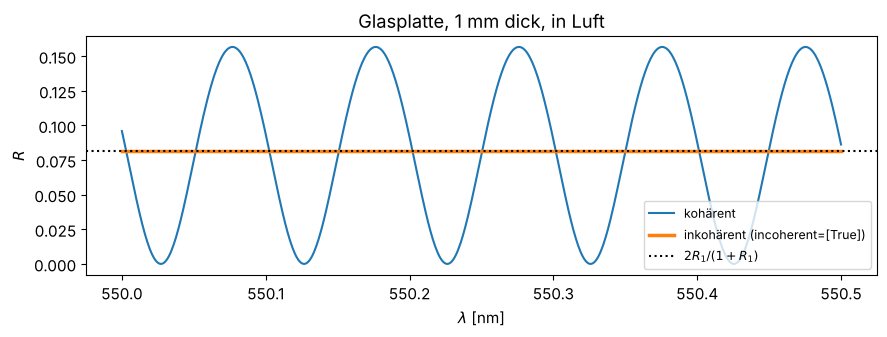

In [10]:
lam = np.linspace(0.5500, 0.5505, 600)
d = 1000.0
R_coh = [stack_RTA(0.0, l, [1.52], [0.0], [d], n_sub=1.0)[0] for l in lam]
R_inc = [stack_RTA(0.0, l, [1.52], [0.0], [d], n_sub=1.0, incoherent=[True], N_phases=64)[0] for l in lam]
R1 = ((1.52 - 1)/(1.52 + 1))**2
fig, ax = plt.subplots(figsize=(9, 3.5))
ax.plot(lam*1000, R_coh, label="kohärent")
ax.plot(lam*1000, R_inc, lw=2.5, label="inkohärent (incoherent=[True])")
ax.axhline(2*R1/(1 + R1), color="k", ls=":", label="$2R_1/(1+R_1)$")
ax.set_xlabel("$\\lambda$ [nm]"); ax.set_ylabel("$R$"); ax.legend(fontsize=9)
ax.set_title("Glasplatte, 1 mm dick, in Luft")
fig.tight_layout()

### 4.5 Dünne Metallfilme: Reflexion, Transmission, Absorption

Ein Silberfilm wird schon nach wenigen 10 nm zum Spiegel und absorbiert dabei
kaum (Silber hat einen sehr kleinen Realteil $n$). Chrom dagegen ($n \approx 3.1 + 3.3i$)
absorbiert stark: Schon ab etwa 10 nm schluckt ein Chromfilm rund 40 % des
Lichts. Solche Filme dienen als Neutraldichtefilter.

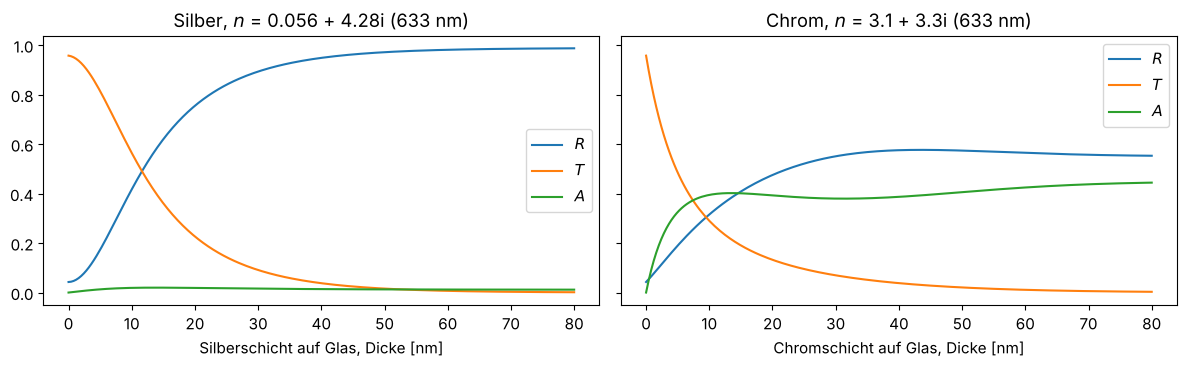

In [11]:
d_vals = np.linspace(0, 0.08, 200)
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), sharey=True)
for ax, (name, n_m) in zip(axes, (("Silber", 0.056 + 4.28j), ("Chrom", 3.1 + 3.3j))):
    RTA = np.array([stack_RTA(0.0, 0.633, [n_m.real], [n_m.imag], [d]) for d in d_vals])
    for i, lab in enumerate(("$R$", "$T$", "$A$")):
        ax.plot(d_vals*1000, RTA[:, i], label=lab)
    ax.set_xlabel(f"{name}schicht auf Glas, Dicke [nm]"); ax.legend()
    ax.set_title(f"{name}, $n$ = {n_m.real} + {n_m.imag}i (633 nm)")
fig.tight_layout()